House Price Prediction Using Gradient Boosting Regression

## Dataset Information

**Dataset Name:** House Sales in King County, USA

**Dataset Source:** Kaggle

**Kaggle Dataset Link:** https://www.kaggle.com/datasets/harlfoxem/housesalesprediction

**Dataset Description:**

The House Sales in King County dataset contains information about house sales in King County, USA. It includes 21,613 records and 21 columns describing various property characteristics, such as the number of bedrooms, bathrooms, living area, location, construction quality and year of construction.

The target variable is `price`, which represents the selling price of each house. This dataset is used to develop a machine learning model that predicts house prices based on property characteristics.

## Problem Statement

House prices vary depending on several factors, such as the size of the property, number of bedrooms and bathrooms, construction quality and geographical location.

Estimating house prices accurately can be challenging because these factors influence property values in different ways.

Therefore, this project aims to develop a machine learning model that predicts house prices based on the available property characteristics using the House Sales in King County, USA dataset.

## Objectives

The main objectives of this project are:

1. To understand and analyse the House Sales in King County dataset.
2. To examine the relationship between different property features and house prices.
3. To identify and handle data quality issues, if any.
4. To perform Exploratory Data Analysis (EDA) using suitable visualizations.
5. To develop a house price prediction model using Gradient Boosting Regression.
6. To evaluate the model using MAE, RMSE and R-squared score.
7. To identify the most important features influencing the model's predictions.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('/content/kc_house_data.csv')

## 3. Data Understanding

The dataset was examined to understand its structure,
dimensions, column names and data types.

It contains 21,613 records and 21 columns, including
property characteristics and house selling prices.

In [12]:
# Display first five rows
pd.set_option('display.max_columns', None)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [8]:
# Display number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 21613
Number of columns: 21


In [9]:
# Display column names

print("Column Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Data Types:
id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


In [13]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Missing values in each column:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0

Statistical Summary:


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## 3. Data Cleaning and Quality Assessment

The dataset contains 21,613 records and 21 columns.
The initial data-quality assessment revealed no missing
values and no duplicate records.

However, some numerical features contain unusually high
or low values. These observations will be investigated
during exploratory data analysis.

The date column will be converted into a datetime format.
The id column will be excluded from model training because
it is an identifier rather than a meaningful house feature.

In [14]:
# Convert date column to datetime format
df['date'] = pd.to_datetime(df['date'])

# Check data types after conversion
print("Updated data types:")
print(df.dtypes)

# Check unusual bedroom values
print("\nBedroom counts:")
print(df['bedrooms'].value_counts().sort_index())

# Check unusual price values
print("\nHighest house prices:")
print(df['price'].nlargest(10))

# Check the date range
print("\nDate range:")
print("Earliest date:", df['date'].min())
print("Latest date:", df['date'].max())

Updated data types:
id                        int64
date             datetime64[ns]
price                   float64
bedrooms                  int64
bathrooms               float64
sqft_living               int64
sqft_lot                  int64
floors                  float64
waterfront                int64
view                      int64
condition                 int64
grade                     int64
sqft_above                int64
sqft_basement             int64
yr_built                  int64
yr_renovated              int64
zipcode                   int64
lat                     float64
long                    float64
sqft_living15             int64
sqft_lot15                int64
dtype: object

Bedroom counts:
bedrooms
0       13
1      199
2     2760
3     9824
4     6882
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

Highest house prices:
7252    7700000.0
3914    7062500.0
9254    6885000.0
4411    5570000.0
1448

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand
the distribution of house prices and relationships
between different house features.

Visualizations are used to identify patterns,
trends and unusual observations in the dataset.

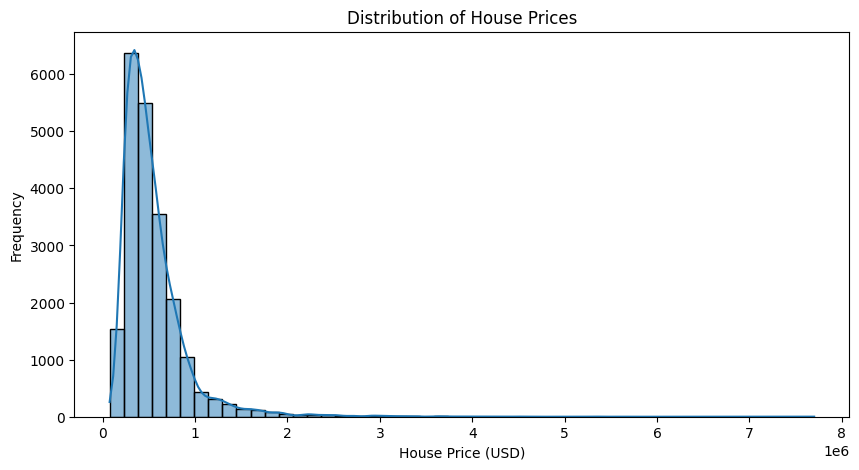

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], bins=50, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price (USD)')
plt.ylabel('Frequency')

plt.show()

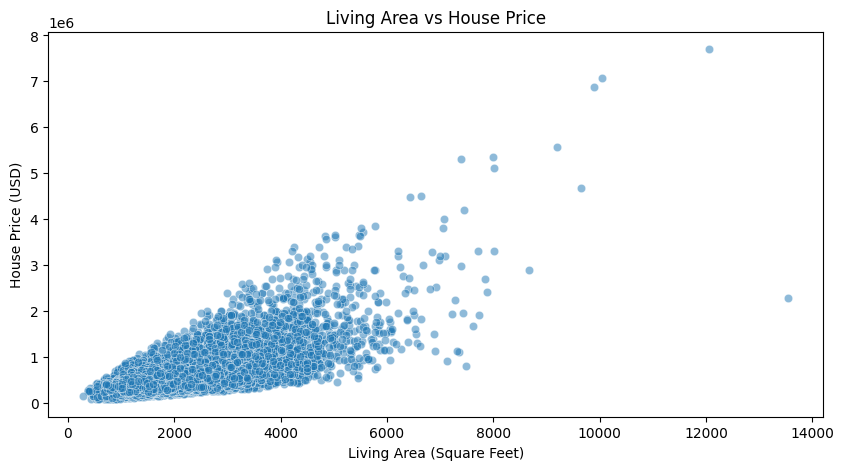

In [16]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='sqft_living',
    y='price',
    alpha=0.5
)

plt.title('Living Area vs House Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price (USD)')

plt.show()

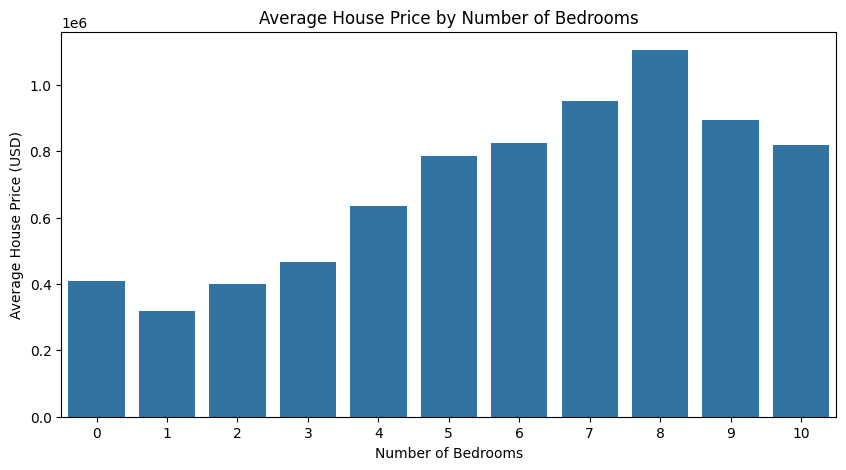

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df[df['bedrooms'] <= 10],
    x='bedrooms',
    y='price',
    errorbar=None
)

plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price (USD)')

plt.show()

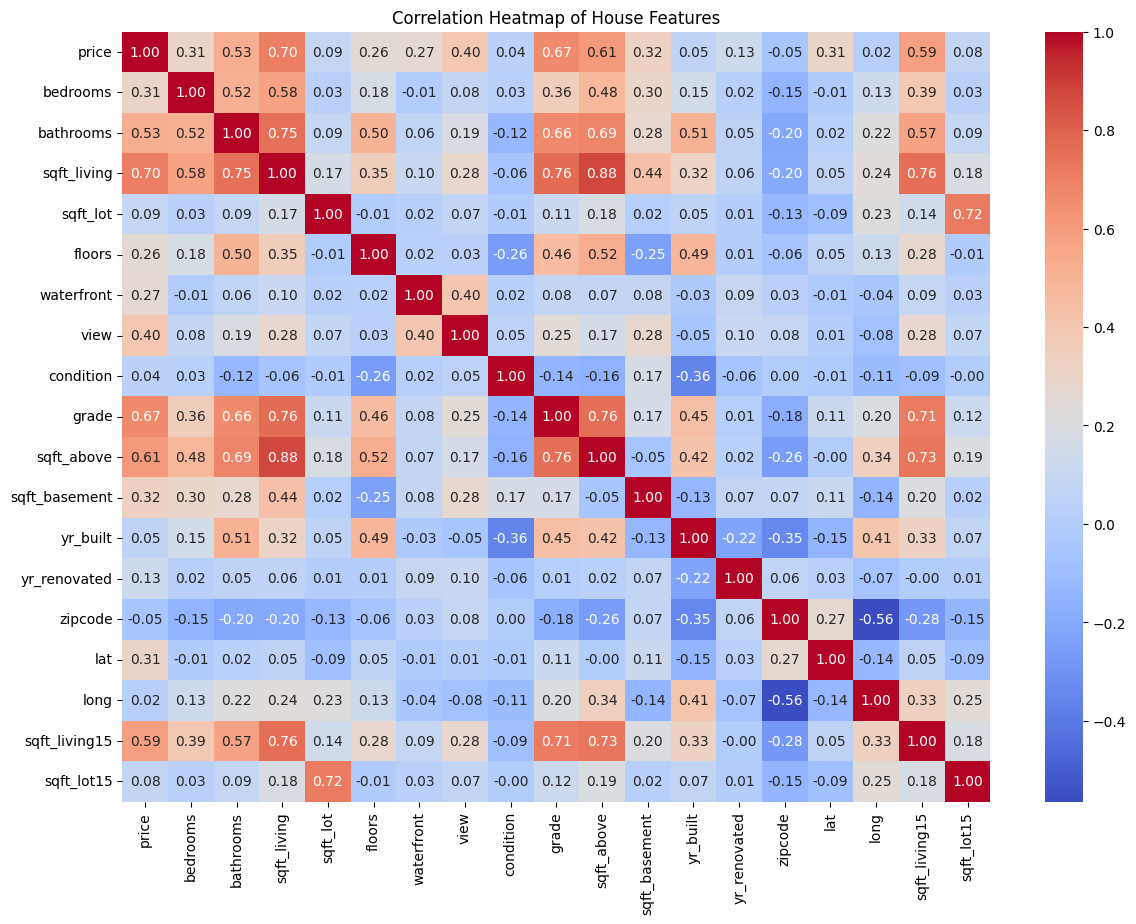

In [18]:
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(include='number').drop(
    columns=['id']
).corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Heatmap of House Features')

plt.show()

### Overall Findings from Exploratory Data Analysis

1. Most houses in the dataset have relatively lower selling prices.
2. House prices show a positively skewed distribution.
3. Living area has a positive relationship with house price.
4. Houses with larger living areas generally have higher prices.
5. The average house price generally increases with the number of bedrooms, although this trend is not consistent for all categories.
6. Living area, grade and above-ground area show relatively strong positive correlations with house price.

The EDA indicates that several property features may help predict house prices.

## 6. Data Preparation and Model Building

The dataset was prepared for machine learning by
extracting year, month and day from the sale date.

The ID and original date columns were removed.
Zipcode was treated as a categorical feature and
converted using One-Hot Encoding.

The dataset was divided into 80% training data
and 20% testing data.

A Gradient Boosting Regression model was trained
using the prepared training data.

In [19]:
# Create a copy of the dataset
model_df = df.copy()

# Extract information from date
model_df['sale_year'] = model_df['date'].dt.year
model_df['sale_month'] = model_df['date'].dt.month
model_df['sale_day'] = model_df['date'].dt.day

# Remove unnecessary columns
model_df = model_df.drop(columns=['id', 'date'])

# Treat zipcode as a categorical feature
model_df['zipcode'] = model_df['zipcode'].astype(str)

# Separate features and target
X = model_df.drop(columns=['price'])
y = model_df['price']

print("Features prepared successfully!")
print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nInput features:")
print(X.columns.tolist())

Features prepared successfully!
Number of input features: 21
Number of target values: 21613

Input features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'sale_day']


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 17290
Testing records: 4323


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor

# Identify categorical and numerical columns
categorical_features = ['zipcode']
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Preprocess categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

# Create Gradient Boosting model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Make predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))

Model Evaluation Results
-------------------------
MAE: 78746.0
RMSE: 142206.03
R-squared: 0.8662


## 6. Model Evaluation

The Gradient Boosting Regression model was evaluated
using a test dataset containing 4,323 records.

The evaluation metrics obtained were:

- Mean Absolute Error (MAE): $78,746.00
- Root Mean Squared Error (RMSE): $142,206.03
- R-squared Score: 0.8662

The R-squared score indicates that the model explains
approximately 86.62% of the variation in house prices.

The results indicate that Gradient Boosting Regression
can learn useful patterns from the selected house features
and provide reasonably informative price predictions.

Top 15 Important Features:


,Feature,Importance
72,remainder__sqft_living,0.330893
78,remainder__grade,0.297187
83,remainder__lat,0.144638
84,remainder__long,0.055176
75,remainder__waterfront,0.035992
81,remainder__yr_built,0.029598
76,remainder__view,0.022183
85,remainder__sqft_living15,0.020512
3,cat__zipcode_98004,0.018660
24,cat__zipcode_98039,0.009787


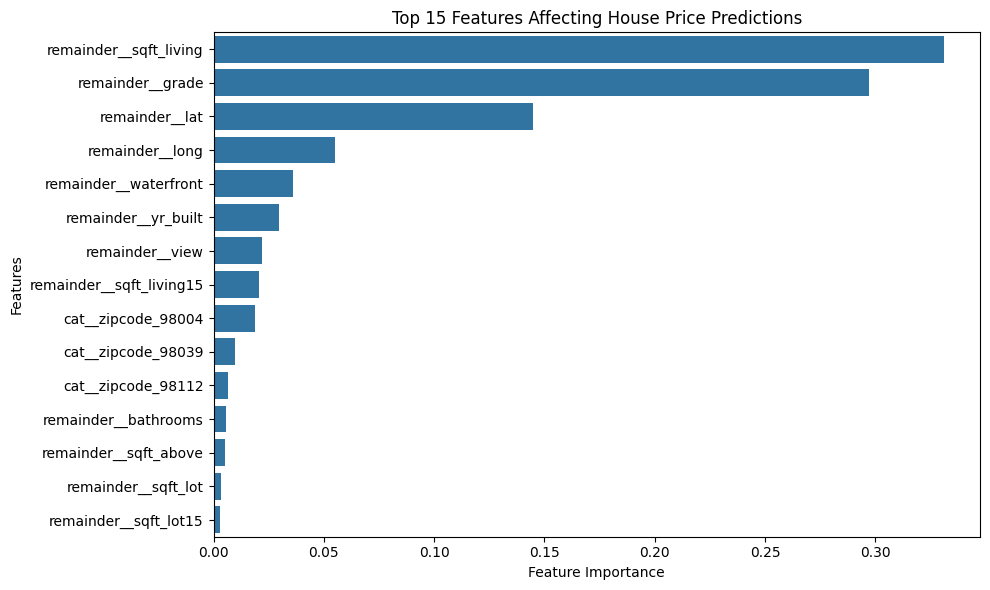

In [23]:
# Get feature names after preprocessing
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance values
importance_values = model.named_steps['regressor'].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort and select the top 15 features
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
).head(15)

# Display the results
print("Top 15 Important Features:")
display(importance_df)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Affecting House Price Predictions')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

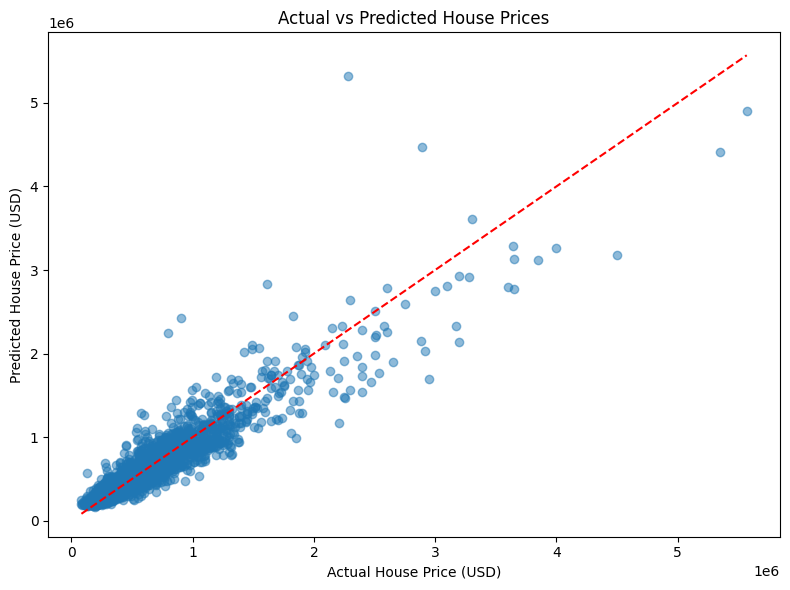

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual House Price (USD)')
plt.ylabel('Predicted House Price (USD)')

plt.tight_layout()
plt.show()

### Feature Importance Analysis

The feature importance analysis shows that living area
(sqft_living) is the most important feature in predicting
house prices, with an importance value of approximately
0.331.

Grade is the second most important feature, followed by
latitude and longitude.

This indicates that property size, construction quality
and geographical location play important roles in the
model's house price predictions.

The results represent the model's predictive feature
importance and do not necessarily indicate causation.

### Actual vs Predicted House Prices

The scatter plot compares actual house prices with
the prices predicted by the Gradient Boosting model.

Most data points are located near the ideal prediction
line, indicating that the model performs reasonably
well on many test records.

However, some points deviate considerably from the
line, particularly among higher-priced properties.
This indicates that the model does not predict every
house price accurately.

## 7. Conclusion

In this project, a house price prediction system was
developed using the House Sales in King County, USA
dataset obtained from Kaggle.

The dataset contained 21,613 records and 21 columns.
Data cleaning and quality assessment were performed,
and no missing values or duplicate records were found.

Exploratory Data Analysis was carried out using
visualizations to understand house price distributions
and relationships between different property features.

A Gradient Boosting Regression model was trained using
80% of the dataset and evaluated using the remaining 20%.

The model achieved the following results:

- MAE: $78,746.00
- RMSE: $142,206.03
- R-squared: 0.8662

The feature importance analysis identified living area,
grade and geographical location as important features
for house price prediction.

Overall, the project demonstrates how machine learning
can be used to estimate house prices based on property
characteristics. Although the model achieved a good
R-squared score, prediction errors were observed,
particularly for some expensive properties.